In [1]:
import pymc as pm
import numpy as np
import arviz as az
import matplotlib.pyplot as plt
from tools import load_csv

kbT = 4.112
force_threshold = 2 # pN Rejection threshold

### Read in the data in a format we can use in PyMC

In [2]:
data = load_csv('stiff40_2.csv')
dt = data['dt']
forces = []
unbinding_at = []
for f in data['F']:
    nan_at = list(np.where(np.isnan(f))[0]) + [len(f)]
    nan_at = nan_at[0]
    forces.append(f[:nan_at])
    unbinding_at.append(nan_at)

forces_cont = np.concatenate(forces)
unbinding_at = np.cumsum(unbinding_at)
bond_breaks = np.zeros_like(forces_cont)
bond_breaks[unbinding_at-1] = 1

### Check if the unbinding events are at the correct location

[None]

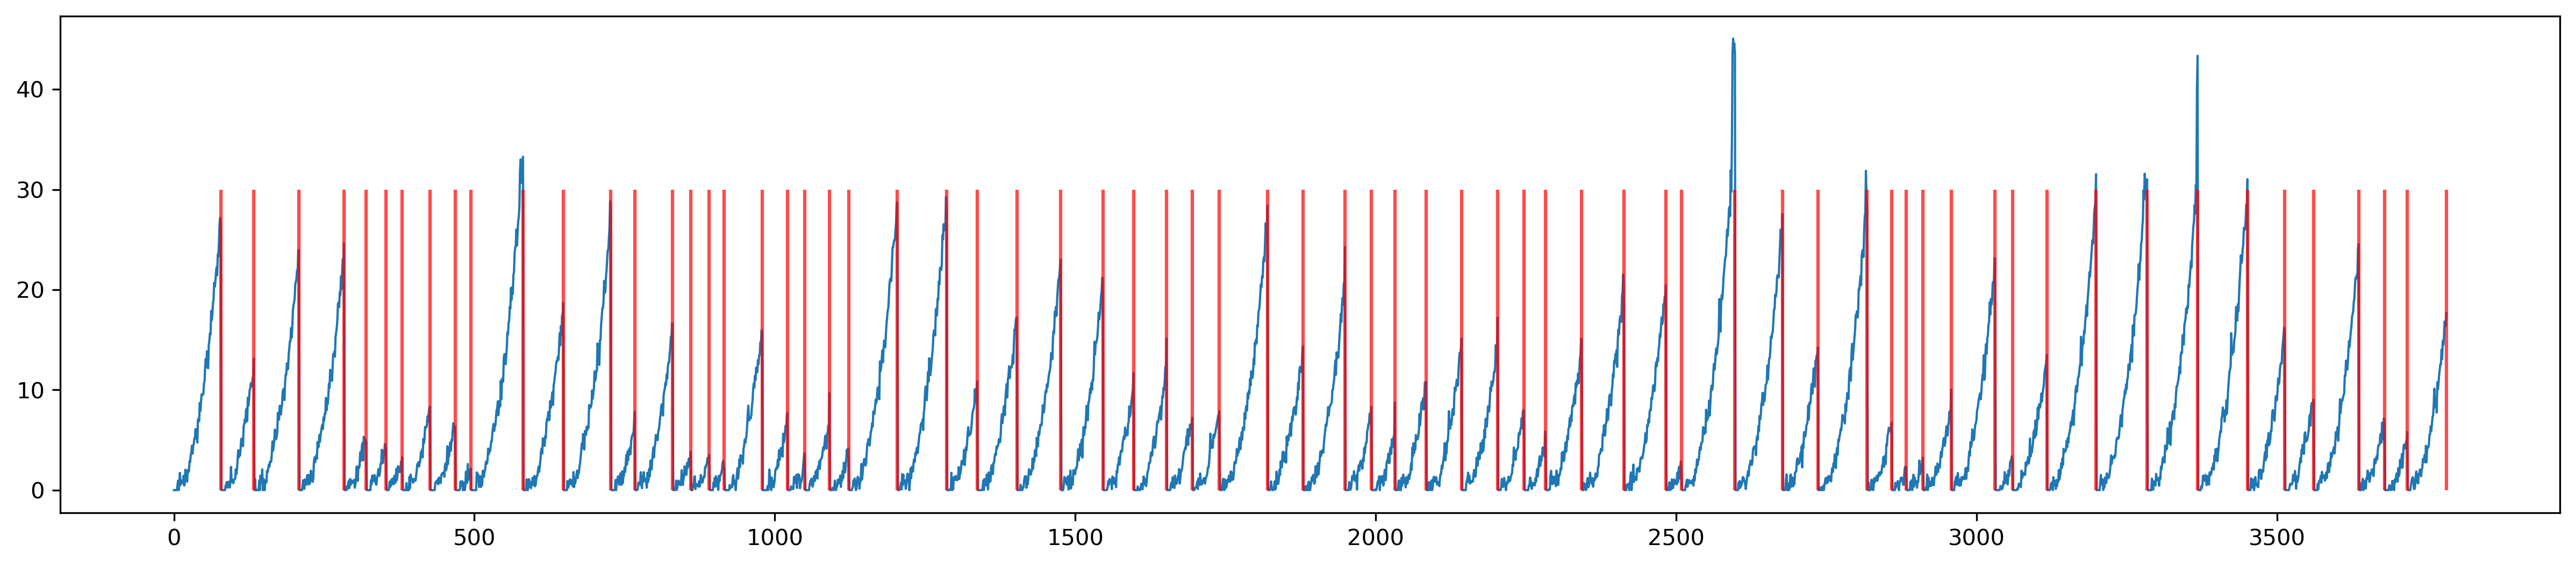

In [3]:
plt.figure(figsize=(20,4), dpi=300)
plt.plot(forces_cont, lw=1)
markerline, stemlines, baseline = plt.stem(bond_breaks*30, 'r')
plt.setp(markerline, alpha=0.0)
plt.setp(stemlines, alpha=0.7)
plt.setp(baseline, alpha=0.0)

### Inference Model

In [4]:
model = pm.Model()

with model:
    ''' PRIORS '''
    ru = pm.Uniform('ru', 0, 0.22)
    xu = pm.Uniform('xu', 0, 1.0)

    ''' UNBINDING PROBABILITY '''
    p_unbind = 1 - pm.math.exp(-dt * ru * pm.math.exp(forces_cont * xu / kbT))

    ''' BERNOULLI HEAD DISTRIBUTION '''
    unbinding = pm.Bernoulli('bond_state', p=p_unbind, observed=bond_breaks)

    ''' REJECTION MODELLING '''
    logp_censor = 0.0
    for f in forces:
        f_below = f[f < force_threshold]
        p_unbind_step = 1.0 - pm.math.exp(- dt * ru * pm.math.exp(xu * f_below / kbT))
        p_survive = pm.math.prod(1.0 - p_unbind_step)
        logp_censor += - pm.math.log(p_survive)

    pm.Potential("threshold_truncation", logp_censor) # Multiply likelihood with correction term
    
    idata = pm.sample(tune=2000, draws=5000, )

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [ru, xu]


Sampling 4 chains for 2_000 tune and 5_000 draw iterations (8_000 + 20_000 draws total) took 26 seconds.


### Plot Traces

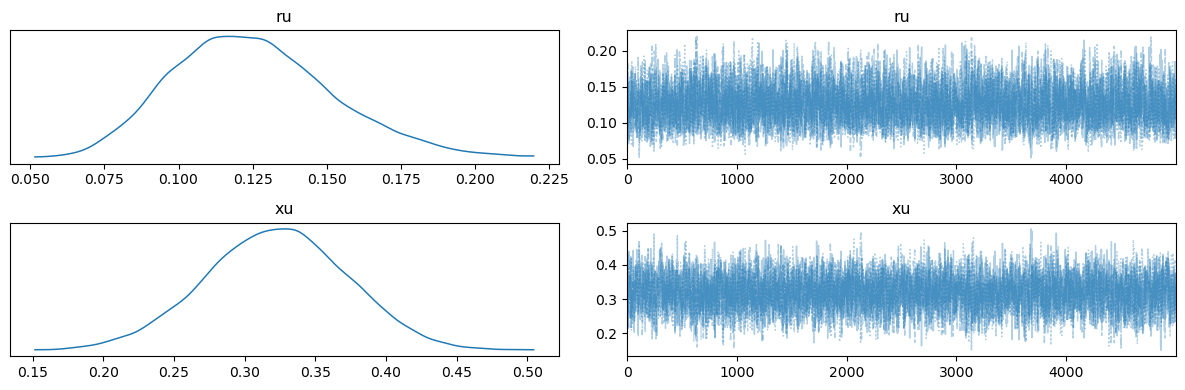

In [5]:
az.plot_trace(idata, combined=True)
plt.tight_layout()

### Posterior

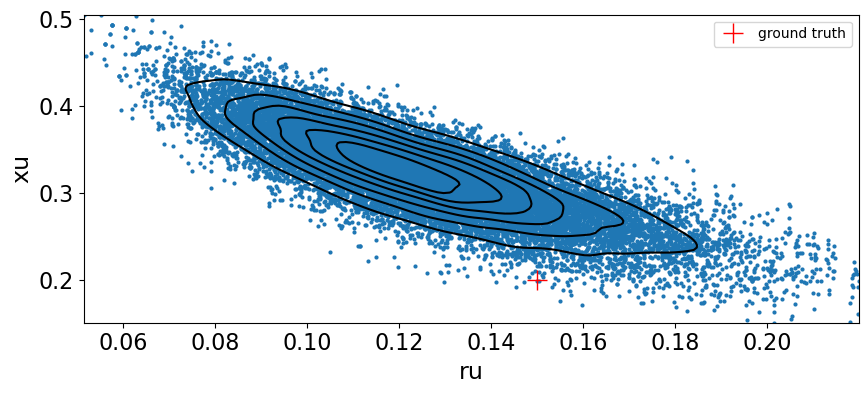

In [9]:
az.plot_pair(idata, kind=['scatter', 'kde'], figsize=(10,4))
plt.plot([0.15], [0.2], '+r', ms=15, label='ground truth')
plt.legend(); plt.show()